# Dissertation Assignment 4
# Exploratory Data Analysis
**Submitted by: Urvi Sharma <br>**
**Roll No: AM.EN.P2ARI2022 <br>**
**Date: 11-Nov-2021**

In [26]:
import pandas as pd
from matplotlib import pyplot as plt
import yaml
import json
from py2neo import Graph
from tqdm import tqdm
from IPython.display import Image
plt.rcParams['figure.figsize'] = [12, 5]
plt.rcParams['figure.dpi'] = 100

In [3]:
reviews = pd.read_csv("reviews.csv")

In [11]:
df = pd.read_csv('normalized_ratings.csv')

The Amazon Reviews Dataset has been obtained from https://jmcauley.ucsd.edu/data/amazon/ This dataset contains product reviews and metadata from Amazon, including 142.8 million reviews spanning May 1996 - July 2014.

This dataset includes reviews (ratings, text, helpfulness votes), product metadata (descriptions, category information, price, brand, and image features), and links (also viewed/also bought graphs).

This project uses a small subset of Amazon Clothing, Shoes and Jewelry data,meant for experimentation.

In [4]:
reviews

,rating,reviewTime,reviewerID,productID,style,reviewerName,reviewText,summary,unixReviewTime,Size,Color
0,5,"09 4, 2015",ALJ66O1Y6SLHA,B000K2PJ4K,"{'Size:': ' Big Boys', 'Color:': ' Blue/Orange'}",Tonya B.,Great product and price!,Five Stars,1441324800,Big Boys,Blue/Orange
1,5,"09 4, 2015",ALJ66O1Y6SLHA,B000K2PJ4K,"{'Size:': ' Big Boys', 'Color:': ' Black (3746...",Tonya B.,Great product and price!,Five Stars,1441324800,Big Boys,Black (37467610) / Red/White
2,5,"09 4, 2015",ALJ66O1Y6SLHA,B000K2PJ4K,"{'Size:': ' Big Boys', 'Color:': ' Blue/Gray L...",Tonya B.,Great product and price!,Five Stars,1441324800,Big Boys,Blue/Gray Logo
3,5,"09 4, 2015",ALJ66O1Y6SLHA,B000K2PJ4K,"{'Size:': ' Big Boys', 'Color:': ' Blue (37867...",Tonya B.,Great product and price!,Five Stars,1441324800,Big Boys,Blue (37867638-99) / Yellow
4,5,"09 4, 2015",ALJ66O1Y6SLHA,B000K2PJ4K,"{'Size:': ' Big Boys', 'Color:': ' Blue/Pink'}",Tonya B.,Great product and price!,Five Stars,1441324800,Big Boys,Blue/Pink
...,...,...,...,...,...,...,...,...,...,...,...
3171,5,"07 2, 2018",A2077NII5H62R2,B005AGO4LU,"{'Size:': ' 8.5 B(M) US', 'Color:': ' Green Gl...",Amazon Customer,Perfect fit!,Five Stars,1530489600,8.5 B(M) US,Green Glow/Seaweed - Hasta - White
3172,5,"06 28, 2018",A2IBS6PIPAGAB5,B005AGO4LU,"{'Size:': ' 5 B(M) US', 'Color:': ' Wolf Grey/...",J. Avila,My favorite cross trainers!,Comfortable,1530144000,5 B(M) US,Wolf Grey/Black-pink Blast/White
3173,5,"06 25, 2018",A1GTC5EVSJNCQ8,B005AGO4LU,"{'Size:': ' 8 B(M) US', 'Color:': ' Blue Tint/...",Amazon Customer,Love them fit perfect,Five Stars,1529884800,8 B(M) US,Blue Tint/Green Glow/Hasta/White
3174,5,"06 20, 2018",A311XHHLM12MUT,B005AGO4LU,"{'Size:': ' 9 B(M) US', 'Color:': ' Blue Tint/...",Peter,Favorite Nike shoe ever! The flex sole is exce...,Love them!,1529452800,9 B(M) US,Blue Tint/Green Glow/Hasta/White


Text(0.5, 0, 'Number of items rated by reviewer')

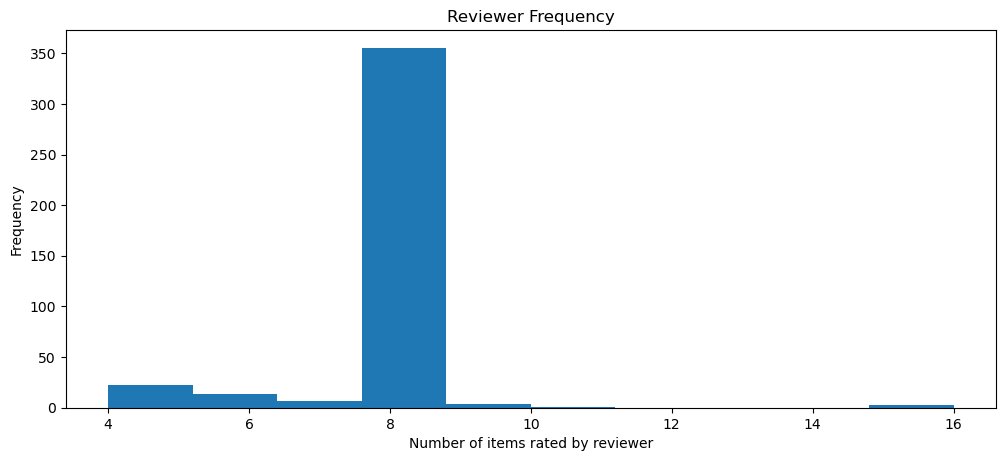

In [5]:
reviews.reviewerID.value_counts().plot(kind = 'hist')
plt.title("Reviewer Frequency")
plt.xlabel("Number of items rated by reviewer")

Above Graph shows that maximum number of items rated by users is 16 and minimum number of items rated is 4 and as we can tell from looking at the frequency most users have rated over 8 items.

Text(0.5, 0, 'Frequency')

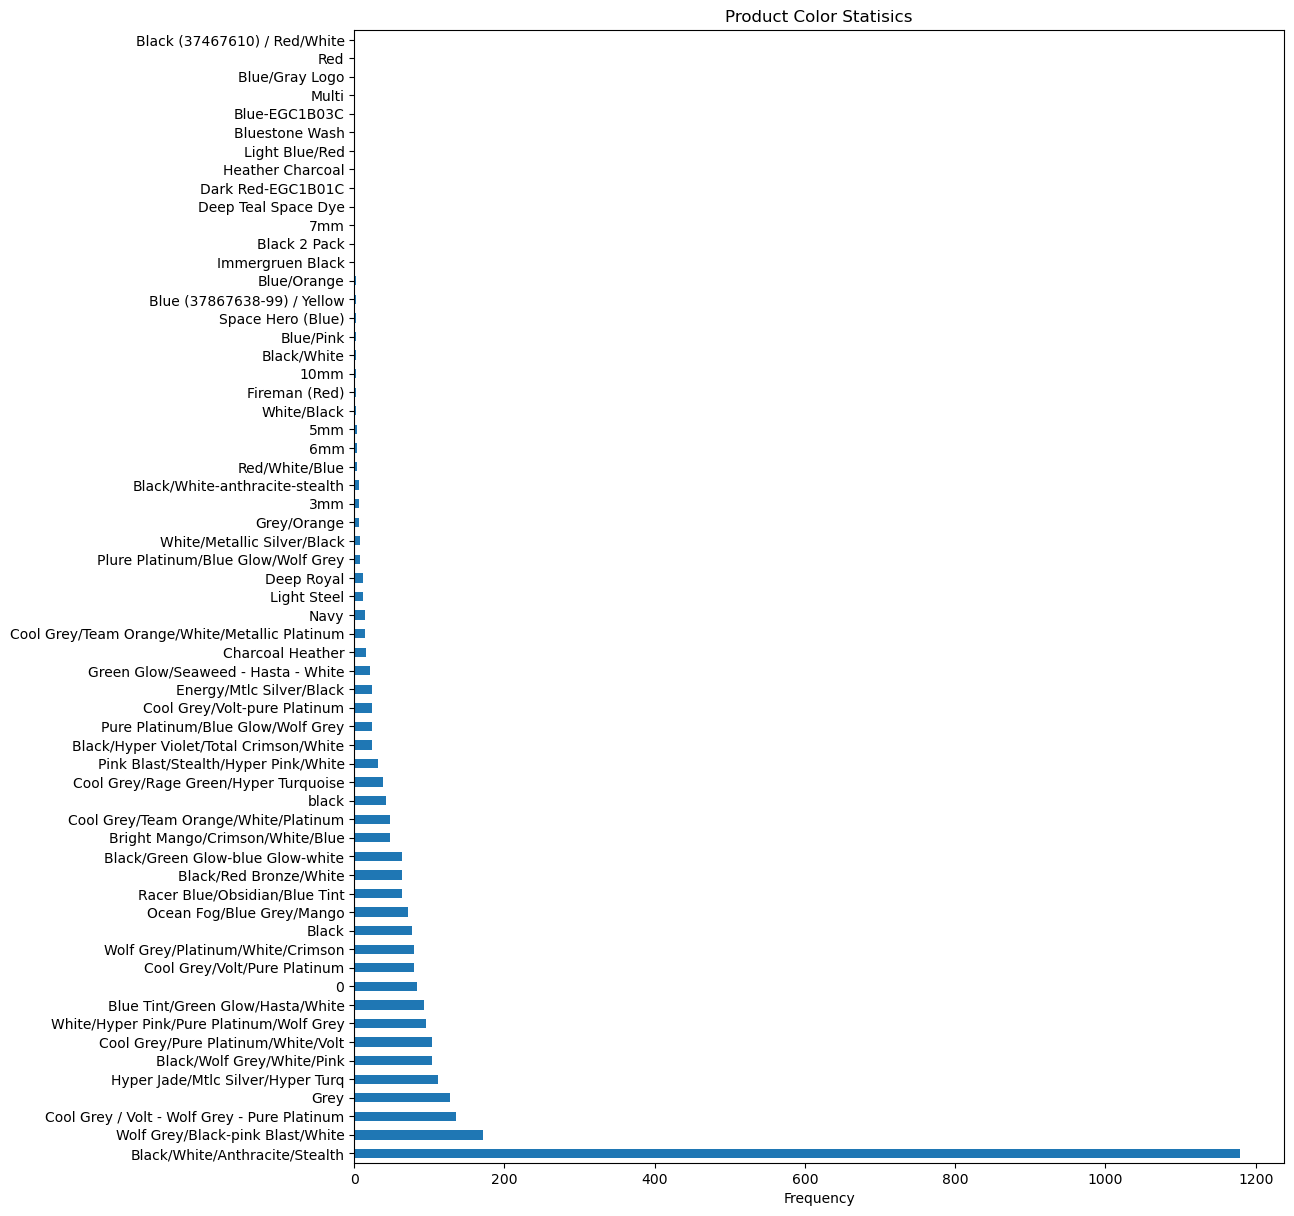

In [6]:
plt.rcParams['figure.figsize'] = [12, 15]
reviews.Color.value_counts().plot(kind = 'barh')
plt.title("Product Color Statisics")
plt.xlabel("Frequency")

In this project product color is an important attribute tag used to identify user preference. The bar graph above gives estimate of color range in items and their frequency.

In [7]:
ratings = pd.read_csv("normalized_ratings.csv")
ratings

,source,target,edge
0,ALJ66O1Y6SLHA,B000K2PJ4K,5.0
1,ALJ66O1Y6SLHA,B000K2PJ4K,5.0
2,ALJ66O1Y6SLHA,B000K2PJ4K,5.0
3,ALJ66O1Y6SLHA,B000K2PJ4K,5.0
4,ALJ66O1Y6SLHA,B000K2PJ4K,5.0
...,...,...,...
3171,A2077NII5H62R2,B005AGO4LU,5.0
3172,A2IBS6PIPAGAB5,B005AGO4LU,5.0
3173,A1GTC5EVSJNCQ8,B005AGO4LU,5.0
3174,A311XHHLM12MUT,B005AGO4LU,5.0


The ratings data has been extracted from the reviewer data for graph creation and implementation and theratings have been normalized between range (1,5). Tje graph below displays the rating frequency.

Text(0.5, 0, 'Ratings')

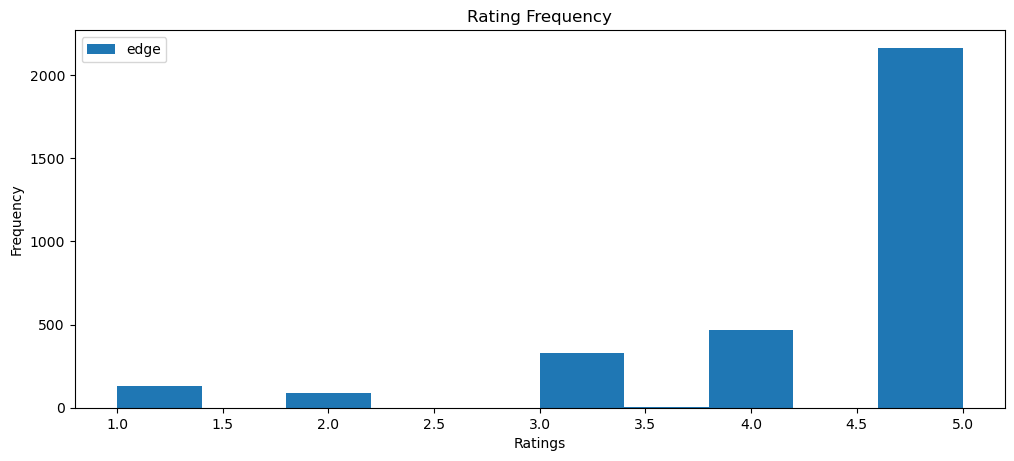

In [8]:
plt.rcParams['figure.figsize'] = [12, 5]
ratings.plot.hist()
plt.title("Rating Frequency")
plt.xlabel("Ratings")


As we can see from the plot above, most items are rated 4 and above, also unlike other recommendation scenarios here ratings don't mean whether user likes the object, since a user won't buy something they don't like, therefore usually low ratings depend more on factors like- damaged product, improper delivery etc.

In [17]:
graph = Graph("bolt://localhost:7687", user="neo4j", password="password")
tx = graph.begin()

In [18]:
for index, row in tqdm(df.iterrows()):
    tx.evaluate(f'''
    MERGE (a:Subject {{name:$Subject}})
    MERGE (b:Object {{name:$Object}})
    MERGE (a)-[r:Relation {{name:$Relation}}]->(b)
    ''', parameters = {'Subject': row['source'], 
                       'Object': row['target'], 
                       'Relation': str(row['edge'])})
tx.commit()


3176it [01:16, 41.38it/s]
<ipython-input-18-856ccbec808f>:9: DeprecationWarning: The transaction.commit() method is deprecated, use graph.commit(transaction) instead
  tx.commit()


### Query the Knowledge Graph

In [19]:
# Number of Nodes
graph.run("""MATCH (n) RETURN COUNT (n)""").data()

[{'COUNT (n)': 437}]

In [20]:
# Number of Relationships
graph.run("""MATCH ()-->() RETURN COUNT(*)""").data()

[{'COUNT(*)': 3060}]

In [21]:
# List node labels
graph.run("""CALL db.labels()""").data()

[{'label': 'Subject'}, {'label': 'Object'}]

In [22]:
# What is related, and how
graph.run("CALL db.schema.visualization()").data()

[{'nodes': [Node('Object', constraints=[], indexes=[], name='Object'),
   Node('Subject', constraints=[], indexes=[], name='Subject')],
  'relationships': [Relation(Node(), Node())]}]

In [25]:
graph.run("""MATCH (m)-[r]-(n) RETURN m,r,n LIMIT 30""").data()

[{'m': Node('Object', name='B000K2PJ4K'),
  'r': Relation(Node('Subject', name='ALJ66O1Y6SLHA'), Node('Object', name='B000K2PJ4K'), name='5.0'),
  'n': Node('Subject', name='ALJ66O1Y6SLHA')},
 {'m': Node('Subject', name='A3W11493KS6Z2L'),
  'r': Relation(Node('Subject', name='A3W11493KS6Z2L'), Node('Object', name='B000K2PJ4K'), name='3.0'),
  'n': Node('Object', name='B000K2PJ4K')},
 {'m': Node('Subject', name='A3W11493KS6Z2L'),
  'r': Relation(Node('Subject', name='A3W11493KS6Z2L'), Node('Object', name='B000K2PJ4K'), name='5.0'),
  'n': Node('Object', name='B000K2PJ4K')},
 {'m': Node('Subject', name='A3W11493KS6Z2L'),
  'r': Relation(Node('Subject', name='A3W11493KS6Z2L'), Node('Object', name='B000K2PJ4K'), name='1.0'),
  'n': Node('Object', name='B000K2PJ4K')},
 {'m': Node('Subject', name='ALJ66O1Y6SLHA'),
  'r': Relation(Node('Subject', name='ALJ66O1Y6SLHA'), Node('Object', name='B000K2PJ4K'), name='5.0'),
  'n': Node('Object', name='B000K2PJ4K')},
 {'m': Node('Object', name='B000K2

<img src="graph.png" width="800" height="400">